# 00 · Qubits, superposition and the Born rule as a generative model

**QGAI open notebooks · Track: Foundations**

Generative AI is about learning a probability distribution and sampling from it.
A quantum circuit *is* a probability distribution: measure it and you get a sample,
with probabilities given by the **Born rule**, $p(x) = |\langle x|\psi\rangle|^2$.

This notebook builds that intuition in four small steps:

1. One qubit in superposition, sampled with finite shots.
2. A parameterised 3-qubit circuit as a tunable distribution over 8 bitstrings.
3. Entanglement: a distribution that no product of independent bits can represent.
4. What this does and does not imply.

Everything runs on a classical simulator in seconds. Random seeds are fixed.

In [1]:
import numpy as np
import pennylane as qml
import matplotlib.pyplot as plt

SEED = 7
rng = np.random.default_rng(SEED)
print("PennyLane", qml.__version__)

PennyLane 0.45.1


## 1. One qubit in superposition

A Hadamard gate takes $|0\rangle$ to $(|0\rangle + |1\rangle)/\sqrt{2}$. The Born rule says each outcome has probability 0.5.
With a finite number of shots, the observed frequencies only *approximate* that, with error shrinking like $1/\sqrt{N}$.

In [2]:
dev_exact = qml.device("default.qubit", wires=1)

@qml.qnode(dev_exact)
def plus_state_probs():
    qml.Hadamard(0)
    return qml.probs(wires=0)

print("Exact Born-rule probabilities:", np.round(plus_state_probs(), 4))

for shots in [10, 100, 1_000, 10_000]:
    dev = qml.device("default.qubit", wires=1, seed=SEED)

    @qml.set_shots(shots)
    @qml.qnode(dev)
    def sample_plus():
        qml.Hadamard(0)
        return qml.sample(wires=0)

    s = np.asarray(sample_plus()).ravel()
    print(f"{shots:>6} shots -> frequency of 1 = {s.mean():.3f}  (|error| = {abs(s.mean() - 0.5):.3f}, 1/sqrt(N) = {1/np.sqrt(shots):.3f})")

Exact Born-rule probabilities: [0.5 0.5]
    10 shots -> frequency of 1 = 0.600  (|error| = 0.100, 1/sqrt(N) = 0.316)
   100 shots -> frequency of 1 = 0.500  (|error| = 0.000, 1/sqrt(N) = 0.100)
  1000 shots -> frequency of 1 = 0.498  (|error| = 0.002, 1/sqrt(N) = 0.032)
 10000 shots -> frequency of 1 = 0.502  (|error| = 0.002, 1/sqrt(N) = 0.010)


## 2. A parameterised circuit is a tunable distribution

Three qubits give $2^3 = 8$ possible bitstrings. Rotation angles $\theta$ and entangling CNOTs shape the distribution $p_\theta(x)$.
Changing $\theta$ changes the distribution, which is what a quantum generative model trains.

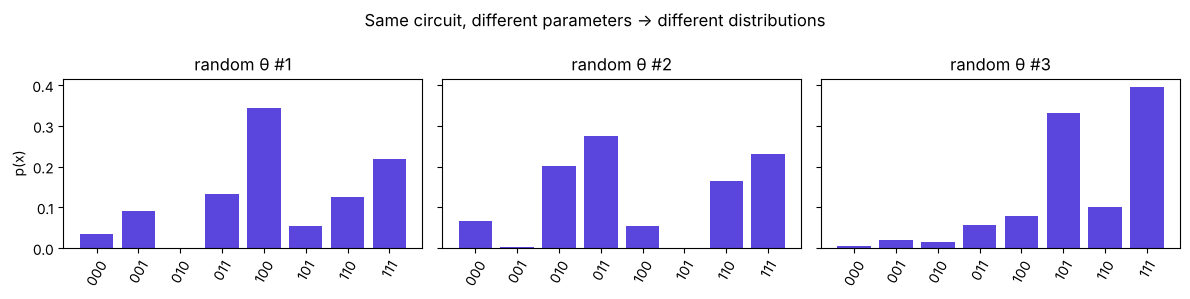

In [3]:
n = 3
dev3 = qml.device("default.qubit", wires=n)

@qml.qnode(dev3)
def circuit_probs(theta):
    for w in range(n):
        qml.RY(theta[w], wires=w)
    qml.CNOT(wires=[0, 1])
    qml.CNOT(wires=[1, 2])
    for w in range(n):
        qml.RY(theta[n + w], wires=w)
    return qml.probs(wires=range(n))

labels = [format(i, f"0{n}b") for i in range(2**n)]
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, k in zip(axes, range(3)):
    theta = rng.uniform(0, np.pi, size=2 * n)
    p = circuit_probs(theta)
    ax.bar(labels, p, color="#5a45dd")
    ax.set_title(f"random θ #{k + 1}")
    ax.tick_params(axis="x", rotation=60)
axes[0].set_ylabel("p(x)")
plt.suptitle("Same circuit, different parameters → different distributions")
plt.tight_layout()
plt.show()

## 3. Entanglement: correlations a product model cannot represent

The Bell state $(|00\rangle + |11\rangle)/\sqrt{2}$ only ever produces `00` or `11`. Each bit on its own is a fair coin.

The best model that treats the two bits as **independent** must use those same fair-coin marginals, so it spreads probability over all four outcomes.
We measure the gap with the KL divergence $D_{KL}(p\,\|\,q) = \sum_x p(x)\log\frac{p(x)}{q(x)}$.

In [4]:
dev2 = qml.device("default.qubit", wires=2)

@qml.qnode(dev2)
def bell_probs():
    qml.Hadamard(0)
    qml.CNOT(wires=[0, 1])
    return qml.probs(wires=[0, 1])

p_bell = np.asarray(bell_probs())
m0 = p_bell[2] + p_bell[3]          # P(first bit = 1)
m1 = p_bell[1] + p_bell[3]          # P(second bit = 1)
q_product = np.array([(1 - m0) * (1 - m1), (1 - m0) * m1, m0 * (1 - m1), m0 * m1])

def kl(p, q, eps=1e-12):
    mask = p > 0
    return float(np.sum(p[mask] * np.log(p[mask] / (q[mask] + eps))))

print("Bell distribution      :", {k: round(float(v), 3) for k, v in zip(["00", "01", "10", "11"], p_bell)})
print("Best independent model :", {k: round(float(v), 3) for k, v in zip(["00", "01", "10", "11"], q_product)})
print(f"KL(Bell || independent) = {kl(p_bell, q_product):.4f} nats  (= log 2 = {np.log(2):.4f})")

Bell distribution      : {'00': 0.5, '01': 0.0, '10': 0.0, '11': 0.5}
Best independent model : {'00': 0.25, '01': 0.25, '10': 0.25, '11': 0.25}
KL(Bell || independent) = 0.6931 nats  (= log 2 = 0.6931)


## 4. What this shows, and what it doesn't

**Shows**
- A measured quantum circuit is a generative model whose sampling step is native: every shot is one sample.
- Entangling gates create correlations that a fully independent model misses entirely (here by exactly $\log 2$ nats).

**Does not show**
- Any *advantage*. A classical model with a single pairwise term captures the Bell distribution perfectly, and an 8- or 16-outcome distribution is trivial to store classically.
- Whether real-world data has the kind of structure quantum circuits capture efficiently. That is the open question QGAI studies, always against strong classical baselines.

Next: **01 · Quantum Circuit Born Machine vs classical baselines** trains such a circuit on data.